# 04 — Sistema híbrido e procura heurística
Objetivo: combinar **regras** (explicáveis, apanham as falhas 'de manual') com **ML** (apanha padrões e antecipa) e **otimizar os parâmetros do híbrido com procura heurística** (conteúdo de procura/heurísticas, CP3).

**Alarme híbrido = (alguma regra crítica ativa) OU (probabilidade do ML ≥ limiar t).**

**O problema de otimização.** O 'estado' a procurar tem 9 componentes: quais das regras K01–K06 contam como críticas (6 bits), o limiar `t` do ML, o limite de vibração da K01 e o limite de desgaste da K05. São 2⁶ máscaras × 3 números reais: um espaço grande demais para testar tudo, daí a procura heurística. **Função de custo:** `custo = c_FN × (falhas não detetadas) + c_FP × (falsos alarmes)`. Uma falha não detetada (avaria, paragem não planeada) custa muito mais que um falso alarme (inspeção desnecessária).

In [1]:
import sys, os; sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.dados import carregar_leituras
from src.hibrido import (Contexto, PADRAO, NOMES, custo, metricas, subida_encosta, algoritmo_genetico,
                         pesquisa_aleatoria, grelha_exaustiva, validar_por_maquina, explicar_hibrido)

df = carregar_leituras()
ml = pd.read_csv('../resultados/previsoes_ml.csv')          # criado no notebook 03
assert (ml.id_leitura.values == df.id_leitura.values).all()
os.makedirs('../resultados', exist_ok=True)
print(df.shape, ml.shape)

(4800, 18) (4800, 12)


## 1. Comparar algoritmos de procura (tarefa `falha`, c_FN/c_FP = 10)
Quatro métodos, com orçamento semelhante (~2000 avaliações), repetidos com 5 sementes: **grelha exaustiva** (referência: todas as máscaras × limiares, mas com vibração/desgaste do manual), **pesquisa aleatória** (linha de base), **subida da encosta** com reinícios e **algoritmo genético**. Aqui otimizamos em todos os dados, só para comparar os *algoritmos* (a avaliação justa vem na secção 3).

In [2]:
y = df['falha'].to_numpy(bool); ctx = Contexto(df, ml['p_RF_falha'])
C_FN, C_FP = 10, 1
linhas = []
_, c_grelha, n_grelha = grelha_exaustiva(ctx, y, C_FN, C_FP)
linhas.append(dict(metodo='Grelha exaustiva', seed='-', custo=c_grelha, avaliacoes=n_grelha))
for s in range(5):
    for nome, f in [('Aleatória', pesquisa_aleatoria), ('Subida da encosta', subida_encosta), ('Genético', algoritmo_genetico)]:
        par, c, n = f(ctx, y, C_FN, C_FP, np.random.default_rng(s))
        linhas.append(dict(metodo=nome, seed=s, custo=c, avaliacoes=n))
busca = pd.DataFrame(linhas)
resumo = busca.groupby('metodo').agg(custo_medio=('custo', 'mean'), custo_min=('custo', 'min'),
                                     custo_max=('custo', 'max'), avaliacoes=('avaliacoes', 'mean')).round(1)
print('Custo sem nenhum sistema:', C_FN * y.sum())
resumo.sort_values('custo_medio')

Custo sem nenhum sistema: 1400


,custo_medio,custo_min,custo_max,avaliacoes
metodo,,,,
Subida da encosta,444.2,440,450,2265.0
Genético,445.8,440,450,2040.0
Aleatória,468.6,455,484,2000.0
Grelha exaustiva,484.0,484,484,2944.0


## 2. Que parâmetros encontrou a procura?
Compara com os valores do manual do técnico.

In [3]:
par, c, _ = algoritmo_genetico(ctx, y, C_FN, C_FP, np.random.default_rng(0))
print('Regras críticas ativas:', [n for n, b in zip(NOMES, par['mask']) if b])
print(f"Limiar do ML t = {par['t']:.2f}   (manual/padrão: 0.50)")
print(f"Limite K01 vibração = {par['vib']:.2f} mm/s   (manual: 6.0)")
print(f"Limite K05 desgaste = {par['desg']:.0f} min   (manual: 200)")
print('Custo:', c)
for i in np.where(ctx.alarme(par) & (y == 1))[0][:3]:
    print(explicar_hibrido(df, ctx, par, i), '| falha real:', df.tipo_falha.iloc[i])

Regras críticas ativas: ['K01', 'K03', 'K04', 'K05', 'K06']
Limiar do ML t = 0.38   (manual/padrão: 0.50)
Limite K01 vibração = 5.91 mm/s   (manual: 6.0)
Limite K05 desgaste = 211 min   (manual: 200)
Custo: 440
ALARME L00051 (MQ01): regra K05 | falha real: TWF
ALARME L00067 (MQ01): regra K04 | falha real: PWF
ALARME L00071 (MQ01): regra K04 | falha real: PWF


## 3. Avaliação justa: otimizar em umas máquinas, testar noutras
Os parâmetros são escolhidos em 3/4 das máquinas e avaliados nas restantes (4 folds, por máquina). Comparamos as 3 abordagens: **Regras** (manual), **ML** (só o limiar otimizado) e **Híbrido**. Cenários: `falha` com c_FN/c_FP = 5, 10 e 20, e `falha_nas_proximas_24h` com custos iguais (nesta tarefa 54% das leituras são positivas, por isso um custo 10:1 levaria a alarmar sempre).

In [4]:
CENARIOS = [('falha', 5), ('falha', 10), ('falha', 20), ('falha_nas_proximas_24h', 1)]
linhas = []
for alvo, cfn in CENARIOS:
    yy = df[alvo].to_numpy(bool); base = cfn * yy.sum()
    A, pars = validar_por_maquina(df, ml[f'p_RF_{alvo}'].to_numpy(), yy, cfn, 1)
    for nome, a in A.items():
        m = metricas(yy, a); c = custo(yy, a, cfn, 1)
        linhas.append(dict(alvo=alvo, c_FN_c_FP=cfn, abordagem=nome, custo=c, poupanca_pct=100 * (1 - c / base),
                           precisao=m['precisao'], recall=m['recall'], F1=m['F1'], FP=m['FP'], FN=m['FN']))
comp = pd.DataFrame(linhas).round(2)
comp.to_csv('../resultados/comparacao_abordagens.csv', index=False)
comp

,alvo,c_FN_c_FP,abordagem,custo,poupanca_pct,precisao,recall,F1,FP,FN
0,falha,5,Regras,493,29.57,0.23,0.94,0.36,448,9
1,falha,5,ML,480,31.43,0.27,0.70,0.39,270,42
2,falha,5,Híbrido (hill-climbing),353,49.57,0.41,0.70,0.51,143,42
3,falha,5,Híbrido (genético),350,50.00,0.38,0.75,0.50,175,35
4,falha,10,Regras,538,61.57,0.23,0.94,0.36,448,9
5,falha,10,ML,675,51.79,0.25,0.74,0.37,315,36
6,falha,10,Híbrido (hill-climbing),536,61.71,0.29,0.82,0.43,286,25
7,falha,10,Híbrido (genético),504,64.00,0.28,0.86,0.43,304,20
8,falha,20,Regras,628,77.57,0.23,0.94,0.36,448,9
9,falha,20,ML,908,67.57,0.17,0.89,0.29,608,15


## 4. Gráfico: poupança face a não ter sistema
Poupança = 1 − custo/custo_sem_sistema (quanto mais alta, melhor).

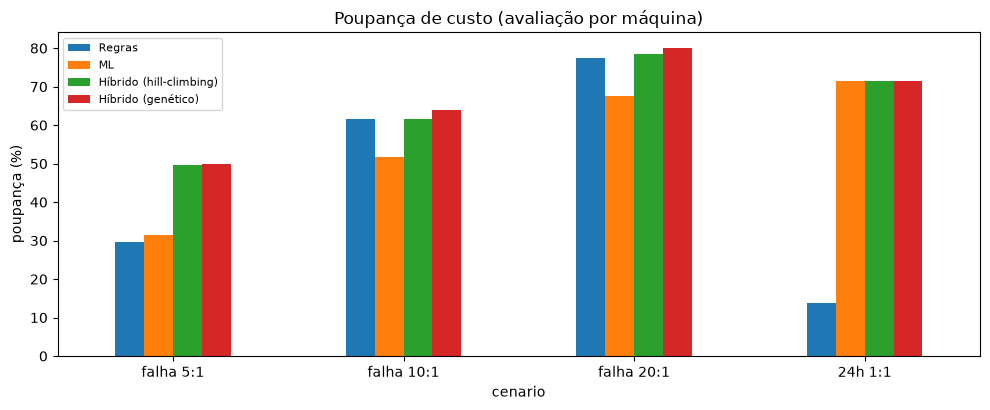

In [5]:
cen = comp.assign(cenario=comp.alvo.str.replace('falha_nas_proximas_24h', '24h') + ' ' + comp.c_FN_c_FP.astype(str) + ':1')
pv = cen.pivot(index='cenario', columns='abordagem', values='poupanca_pct')[['Regras', 'ML', 'Híbrido (hill-climbing)', 'Híbrido (genético)']]
pv = pv.loc[['falha 5:1', 'falha 10:1', 'falha 20:1', '24h 1:1']]
pv.plot.bar(figsize=(10, 4.2), rot=0); plt.ylabel('poupança (%)'); plt.title('Poupança de custo (avaliação por máquina)')
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig('../figuras/comparacao_abordagens.png', dpi=150); plt.show()

#### Conclusões do Passo 4 

O sistema híbrido combina regras e Random Forest: gera um alarme quando uma regra crítica dispara ou quando a probabilidade prevista pelo modelo ultrapassa um determinado limiar. As regras tratam casos evidentes e o ML deteta padrões mais difíceis de identificar.

Na otimização, o algoritmo genético (custo médio 446) e a subida da encosta (444) obtiveram melhores resultados do que a pesquisa aleatória (469) e a grelha exaustiva (484). Os valores encontrados ajustaram alguns parâmetros: a K02 deixou de ser considerada regra crítica, a vibração da K01 passou de 6,0 para cerca de 5,9 mm/s, o desgaste da K05 aumentou para cerca de 211 min e o limiar do ML desceu de 0,50 para 0,38.

Os resultados mostram que a melhor solução depende do custo dos erros.Com custos mais elevados (10:1 e 20:1), o híbrido continua melhor, mas por uma margem menor (64,0% contra 61,6% e 80,1% contra 77,6%), e o ML sozinho fica abaixo das regras (51,8% e 67,6%).

Na previsão de falha_nas_proximas_24h, o híbrido apresenta praticamente o mesmo resultado do ML (71,4% vs. 71,5%), porque as regras identificam apenas 18% das situações de pré-falha e acrescentam pouca informação.

Em geral, o híbrido praticamente nunca é pior do que a melhor abordagem individual: a vantagem é grande com custo 5:1, modesta (cerca de 2 pontos) com custos mais altos e nula na antecipação a 24 h. Como limitações, importa referir que os custos utilizados são apenas estimativas, os dados são sintéticos e existem apenas 140 falhas, o que reduz a fiabilidade de algumas comparações e pode introduzir uma pequena fuga de informação nos resultados.